# 04 – Phát hiện giao dịch bất thường

**Mục tiêu:** phát hiện những giao dịch khác thường mà rule không định nghĩa trước được, ví dụ số tiền lệch hẳn so với thói quen của người chi, hay người chi mua ở loại cửa hàng chưa từng mua. Đây là bước 5 trong luồng nghiệp vụ.

**Thiết kế**
- **Không có nhãn gian lận**, nên dùng phương pháp không giám sát: **Isolation Forest** (`src/anomaly.py`).
- **Đặc trưng theo thói quen chi tiêu:** mỗi giao dịch chỉ được so với các giao dịch **trước nó**, không dùng thông tin tương lai (có kiểm thử trong `tests/test_anomaly.py`).
- **Chia theo thời gian:**
  - 07–09/2025: chỉ làm lịch sử khởi đầu;
  - 10/2025–03/2026: huấn luyện;
  - 04–05/2026: chọn ngưỡng;
  - 06–08/2026: kiểm tra.
- **Đánh giá:** tạo **giao dịch bất thường giả lập** (có nhãn) trong giai đoạn kiểm tra bằng cách biến đổi giao dịch thật (thay thế bản gốc) hoặc thêm cụm mua dồn, rồi đo xem mô hình xếp chúng lên đầu được bao nhiêu.
- **Giải thích:** dùng **SHAP** để biết đặc trưng nào làm giao dịch bị coi là bất thường, rồi chuyển thành câu tiếng Việt cho kế toán và cho LLM.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import joblib, shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from src.data_loader import load_pcard
from src.labels import add_expense_group
from src.anomaly import (build_features, train_iforest, anomaly_score, zscore_baseline, inject_anomalies, apply_injection,
                         explain, FEATURES, ALL_FEATURES, FEATURE_NAMES,
                         build_day_features, describe_day, day_flags_to_transactions, DAY_FEATURES, DAY_FEATURE_NAMES)
from src.rules import run_rules, risk_level, load_reference
from src.risk import combine_risk, LEVELS

pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 110)
BLUE, ORANGE, INK, INK2, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'font.family': ['Arial', 'DejaVu Sans'], 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'figure.dpi': 110, 'figure.facecolor': 'white',
})
P = lambda s: pd.Period(s, 'M')
TRAIN_START, TRAIN_END, VALID_END, TEST_START = P('2025-10'), P('2026-03'), P('2026-05'), P('2026-06')

## 1. Dữ liệu và giao dịch bất thường giả lập

In [2]:
df = add_expense_group(load_pcard())
inj = inject_anomalies(df, TEST_START)
full = apply_injection(df, inj)   # giao dịch bị biến đổi thay thế bản gốc; cụm mua dồn là giao dịch thêm mới

desc = {
    'spike': 'Số tiền gấp 8–15 lần, vẫn dưới hạn mức $5.000 nên rule R02 không bắt',
    'unusual_merchant': 'Người chi mua ở cửa hàng thuộc nhóm chi phí họ chưa từng chi',
    'burst': '6 giao dịch trong cùng một ngày (số tiền, cửa hàng lấy từ lịch sử của chính người đó)',
    'late_post': 'Ghi sổ trễ 45–200 ngày sau ngày mua',
}
pd.DataFrame({'Số giao dịch': inj.inject_type.value_counts(), 'Mô tả': pd.Series(desc)})

,Số giao dịch,Mô tả
burst,396,"6 giao dịch trong cùng một ngày (số tiền, cửa hàng lấy từ lịch sử của chính người đó)"
late_post,400,Ghi sổ trễ 45–200 ngày sau ngày mua
spike,400,"Số tiền gấp 8–15 lần, vẫn dưới hạn mức $5.000 nên rule R02 không bắt"
unusual_merchant,400,Người chi mua ở cửa hàng thuộc nhóm chi phí họ chưa từng chi


In [3]:
t0 = time.time()
X_real = build_features(df)       # dữ liệu thật: dùng để huấn luyện, chọn ngưỡng, phân tích
X_full = build_features(full)     # có giao dịch giả lập: chỉ dùng để đánh giá
print(f'Tính đặc trưng: {time.time() - t0:.1f} giây | {len(X_real):,} giao dịch (đã bỏ hoàn tiền)')
month_real, month_full = df.loc[X_real.index, 'month'], full.loc[X_full.index, 'month']
train = X_real[(month_real >= TRAIN_START) & (month_real <= TRAIN_END)]
valid = X_real[(month_real > TRAIN_END) & (month_real <= VALID_END)]
test_full = X_full[month_full >= TEST_START]
y = full.loc[test_full.index, 'is_injected'].values
inj_type = full.loc[test_full.index, 'inject_type']
print(f'Huấn luyện: {len(train):,} | Chọn ngưỡng: {len(valid):,} | Kiểm tra: {len(test_full):,} (trong đó {y.sum():,} giả lập, {y.mean():.1%})')

Tính đặc trưng: 3.1 giây | 469,070 giao dịch (đã bỏ hoàn tiền)
Huấn luyện: 194,962 | Chọn ngưỡng: 71,100 | Kiểm tra: 101,043 (trong đó 1,581 giả lập, 1.6%)


## 2. Đặc trưng

In [4]:
pd.DataFrame({'Ý nghĩa': [FEATURE_NAMES[f] for f in ALL_FEATURES],
              'Dùng trong mô hình': ['✓' if f in FEATURES else '' for f in ALL_FEATURES]}, index=ALL_FEATURES)

,Ý nghĩa,Dùng trong mô hình
log_amount,Số tiền,✓
z_cardholder,Lệch so với mức chi thường ngày của người chi,✓
z_merchant,Lệch so với mức thường chi tại cửa hàng này,✓
z_group,Lệch so với mức thường chi của nhóm chi phí,
z_agency_group,Lệch so với mức chi của đơn vị cho nhóm chi phí này,✓
log_n_cardholder,Độ dài lịch sử của người chi,
log_n_merchant,Số giao dịch trước đó tại cửa hàng,
new_cardholder_merchant,Lần đầu người này mua ở cửa hàng này,✓
new_cardholder_group,Lần đầu người này chi cho nhóm chi phí này,✓
log_days_since_last,Khoảng cách tới giao dịch trước của người chi,


- Các đặc trưng `z_*` là độ lệch của log(số tiền) so với trung bình các giao dịch trước đó, theo người chi, theo cửa hàng, theo nhóm chi phí và theo đơn vị × nhóm. Chỉ lấy phía **cao hơn** thói quen, vì chi ít bất thường không phải mối quan tâm của kiểm soát chi, và chỉ tính khi đã có ít nhất 3 giao dịch trước đó.
- `burst_ratio` so số giao dịch trong ngày với nhịp mua thường ngày của **chính người đó**, chứ không dùng một con số tuyệt đối chung cho mọi người.
- Mô hình chỉ dùng **8 đặc trưng tập trung**. Lý do nằm ở mục 3.

## 3. So sánh mô hình

In [5]:
def evaluate(name, s):
    s = np.asarray(s)
    thr1, thr3 = np.quantile(s, .99), np.quantile(s, .97)
    row = {'Mô hình': name, 'ROC-AUC': roc_auc_score(y, s), 'PR-AUC': average_precision_score(y, s),
           'Bắt được trong top 1%': (s[y == 1] >= thr1).mean(), 'Bắt được trong top 3%': (s[y == 1] >= thr3).mean()}
    for t in desc:
        row[t] = (s[(inj_type == t).values] >= thr3).mean()
    return row

t0 = time.time()
model_all = train_iforest(train, features=ALL_FEATURES)
model = train_iforest(train)                       # 8 đặc trưng tập trung
print(f'Huấn luyện 2 mô hình: {time.time() - t0:.1f} giây')
res = pd.DataFrame([
    evaluate('Mốc: độ lệch z lớn nhất', zscore_baseline(test_full)),
    evaluate('Isolation Forest – 15 đặc trưng', anomaly_score(model_all, test_full)),
    evaluate('Isolation Forest – 8 đặc trưng tập trung', anomaly_score(model, test_full)),
]).set_index('Mô hình')
res.style.format({c: '{:.3f}' for c in ['ROC-AUC', 'PR-AUC']} | {c: '{:.0%}' for c in res.columns[2:]}) \
   .highlight_max(color='#dbe8f8')

Huấn luyện 2 mô hình: 3.1 giây


,ROC-AUC,PR-AUC,Bắt được trong top 1%,Bắt được trong top 3%,spike,unusual_merchant,burst,late_post
Mô hình,,,,,,,,
Mốc: độ lệch z lớn nhất,0.618,0.045,7%,13%,37%,11%,1%,4%
Isolation Forest – 15 đặc trưng,0.825,0.083,9%,22%,19%,42%,4%,23%
Isolation Forest – 8 đặc trưng tập trung,0.870,0.187,20%,44%,28%,42%,4%,100%


Bốn cột cuối là tỷ lệ bắt được trong top 3% theo từng loại bất thường.

**Nhận xét:**
- **Isolation Forest với 8 đặc trưng tập trung** tốt nhất trên hầu hết các chỉ số. Dùng cả 15 đặc trưng lại kém hơn: các đặc trưng như độ dài lịch sử, cuối tuần, số tiền chẵn khiến mô hình cô lập những giao dịch "hiếm nhưng vô hại", làm loãng tín hiệu thật.
- **Mốc z-score** bắt tốt loại số tiền tăng đột biến (vốn đúng là thứ z-score đo), nhưng bỏ sót hầu hết các loại khác. Isolation Forest kết hợp được nhiều tín hiệu cùng lúc.
- **Ghi sổ trễ** được phát hiện gần như tuyệt đối. **Cửa hàng lạ** và **số tiền tăng đột biến** chỉ bắt được khoảng 30–40%: nhiều người chi có thói quen rất đa dạng (mua ở nhiều loại cửa hàng, số tiền dao động lớn), nên mức tăng 8–15 lần hay một loại cửa hàng mới vẫn nằm trong khoảng bình thường của họ.

### Giới hạn: bất thường theo cụm

Loại **mua dồn dập** gần như không phát hiện được. Lý do là từng giao dịch trong cụm đều bình thường (số tiền quen thuộc, cửa hàng quen thuộc), chỉ **cả cụm** trong ngày mới bất thường. Trong khi đó, dữ liệu thật vốn đã có nhiều ngày mua dồn tự nhiên:

In [6]:
real_test = X_real[month_real >= TEST_START]
burst_rows = test_full.loc[(inj_type == 'burst').values]
pd.DataFrame({'Giao dịch thật (kiểm tra)': real_test.burst_ratio.quantile([.5, .9, .97, .99]),
              'Cụm mua dồn giả lập': burst_rows.burst_ratio.quantile([.5, .9, .97, .99])}).round(2) \
  .rename_axis('Phân vị')

,Giao dịch thật (kiểm tra),Cụm mua dồn giả lập
Phân vị,,
0.50,0.80,3.56
0.90,2.00,6.00
0.97,3.10,7.00
0.99,4.67,8.09


Đây là giới hạn đã biết của các mô hình chấm điểm **từng giao dịch** (point anomaly) khi gặp **bất thường theo cụm** (collective anomaly). Cách xử lý: chấm điểm thêm ở cấp **người chi × ngày** (mục 3b).

## 3b. Mở rộng: phát hiện mua dồn dập ở cấp người chi × ngày

Gộp giao dịch theo **người chi × ngày**, rồi so với các **ngày trước đó** của chính người đó (cần ít nhất 5 ngày có mua):

In [7]:
pd.DataFrame({'Ý nghĩa': pd.Series(DAY_FEATURE_NAMES)})

,Ý nghĩa
poisson_surprise,Độ hiếm của số giao dịch trong ngày (theo phân phối Poisson với nhịp mua thường ngày)
rate_ratio,Số giao dịch trong ngày so với trung bình mỗi ngày có mua
z_total,Tổng tiền trong ngày so với các ngày trước
merch_ratio,Số cửa hàng khác nhau trong ngày so với bình thường
log_n,Số giao dịch trong ngày


`poisson_surprise` = −log P(N ≥ n) với N ~ Poisson(λ), trong đó λ là số giao dịch trung bình mỗi ngày có mua của người đó. Nhờ vậy cùng là 7 giao dịch một ngày, nhưng với người bình thường mua 1 lần/ngày thì rất hiếm, còn với thẻ mua hàng chung của cả phòng thì bình thường.

In [8]:
t0 = time.time()
day_real, day_full = build_day_features(df), build_day_features(full)
burst_keys = full.loc[full.inject_type.eq('burst'), ['cardholder_id', 'tx_date']].drop_duplicates()
day_full['is_burst'] = day_full.merge(burst_keys.assign(b=1), on=['cardholder_id', 'tx_date'], how='left')['b'].fillna(0).astype(int).values
print(f'Đặc trưng cấp ngày: {time.time() - t0:.1f} giây | {len(day_real):,} người chi × ngày')

day_train = day_real[(day_real.month >= TRAIN_START) & (day_real.month <= TRAIN_END)]
day_valid = day_real[(day_real.month > TRAIN_END) & (day_real.month <= VALID_END)]
day_test = day_full[day_full.month >= TEST_START]
y_day = day_test.is_burst.values
day_model = train_iforest(day_train, features=DAY_FEATURES)

def eval_day(name, s):
    s = np.asarray(s); t1, t3 = np.quantile(s, .99), np.quantile(s, .97)
    return {'Cách chấm': name, 'ROC-AUC': roc_auc_score(y_day, s), 'PR-AUC': average_precision_score(y_day, s),
            'Ngày mua dồn trong top 1%': (s[y_day == 1] >= t1).mean(), 'Trong top 3%': (s[y_day == 1] >= t3).mean()}

print(f'Ngày kiểm tra: {len(day_test):,}, trong đó {y_day.sum()} ngày có cụm mua dồn giả lập')
pd.DataFrame([eval_day('Chỉ số Poisson', day_test.poisson_surprise),
              eval_day('Isolation Forest cấp ngày (5 đặc trưng)', anomaly_score(day_model, day_test))]).set_index('Cách chấm') \
  .style.format({'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}', 'Ngày mua dồn trong top 1%': '{:.0%}', 'Trong top 3%': '{:.0%}'})

Đặc trưng cấp ngày: 0.7 giây | 254,233 người chi × ngày


Ngày kiểm tra: 55,318, trong đó 65 ngày có cụm mua dồn giả lập


,ROC-AUC,PR-AUC,Ngày mua dồn trong top 1%,Trong top 3%
Cách chấm,,,,
Chỉ số Poisson,0.993,0.080,88%,100%
Isolation Forest cấp ngày (5 đặc trưng),0.995,0.154,89%,97%


In [9]:
day_threshold = anomaly_score(day_model, day_valid).quantile(0.99)
day_score_real = anomaly_score(day_model, day_real)
day_flag_real = day_score_real >= day_threshold
print(f'Tỷ lệ ngày bị gắn cờ (kiểm tra, dữ liệu thật): {day_flag_real[day_real.month >= TEST_START].mean():.2%}')
top_days = day_real[day_flag_real & (day_real.month >= TEST_START)].assign(score=day_score_real) \
    .sort_values('score', ascending=False).head(5)
for _, r in top_days.iterrows():
    print('-', describe_day(r))

Tỷ lệ ngày bị gắn cờ (kiểm tra, dữ liệu thật): 0.80%
- Người chi có 72 giao dịch tại 1 cửa hàng trong ngày 07/07/2026, trong khi trung bình chỉ 3.0 giao dịch mỗi ngày có mua (gần như không thể xảy ra ngẫu nhiên); tổng $20,373.54, gấp 44.8 lần tổng tiền một ngày thường gặp.
- Người chi có 32 giao dịch tại 15 cửa hàng trong ngày 09/06/2026, trong khi trung bình chỉ 2.3 giao dịch mỗi ngày có mua (gần như không thể xảy ra ngẫu nhiên); tổng $11,752.61, gấp 25.2 lần tổng tiền một ngày thường gặp.
- Người chi có 51 giao dịch tại 3 cửa hàng trong ngày 23/06/2026, trong khi trung bình chỉ 2.3 giao dịch mỗi ngày có mua (gần như không thể xảy ra ngẫu nhiên); tổng $1,993.19, gấp 11.0 lần tổng tiền một ngày thường gặp.
- Người chi có 47 giao dịch tại 1 cửa hàng trong ngày 09/06/2026, trong khi trung bình chỉ 1.6 giao dịch mỗi ngày có mua (gần như không thể xảy ra ngẫu nhiên); tổng $20,723.57, gấp 34.1 lần tổng tiền một ngày thường gặp.
- Người chi có 51 giao dịch tại 4 cửa hàng trong ngày 01/07/202

**Nhận xét:** ở cấp ngày, các cụm mua dồn giả lập gần như đều nằm trong top 1% số ngày đáng ngờ nhất, trong khi mô hình chấm từng giao dịch chỉ bắt được khoảng 4%. Hai mô hình bổ sung cho nhau: một mô hình nhìn **từng giao dịch**, một mô hình nhìn **cả ngày** của người chi. Một giao dịch bị coi là bất thường nếu bị **một trong hai** mô hình gắn cờ.

## 4. Chọn ngưỡng và kết hợp với rule

**Ngưỡng:** giao dịch có điểm bất thường thuộc **top 1%** của giai đoạn chọn ngưỡng (04–05/2026) sẽ bị gắn cờ, tức khoảng 1% giao dịch, tương đương vài trăm giao dịch mỗi tháng.

Câu hỏi quan trọng: **mô hình có bắt được những gì rule bỏ sót không?** Bảng dưới chạy cả rule engine và mô hình trên các giao dịch giả lập.

In [10]:
threshold = anomaly_score(model, valid).quantile(0.99)
score_full = anomaly_score(model, test_full)
day_flag_full = anomaly_score(day_model, day_full) >= day_threshold
tx_day_flag_full = day_flags_to_transactions(full, day_full, day_flag_full)
budgets, approved = load_reference()
rule_full = risk_level(full, run_rules(full, budgets=budgets, approved=approved))

t = pd.DataFrame({
    'type': inj_type.values,
    'rule': (rule_full.loc[test_full.index] != 'Bình thường').values,
    'model_tx': (score_full >= threshold).values,
    'model': (score_full >= threshold).values | tx_day_flag_full.loc[test_full.index].values,
})[y == 1]
comp = t.groupby('type')[['rule', 'model_tx', 'model']].mean()
comp['Rule hoặc mô hình'] = t.assign(any=t.rule | t.model).groupby('type')['any'].mean()
comp.loc['Tất cả'] = [t.rule.mean(), t.model_tx.mean(), t.model.mean(), (t.rule | t.model).mean()]
comp.columns = ['Rule bắt được', 'Mô hình giao dịch (top 1%)', 'Mô hình giao dịch + mô hình ngày', 'Rule hoặc mô hình']
comp.style.format('{:.0%}')

,Rule bắt được,Mô hình giao dịch (top 1%),Mô hình giao dịch + mô hình ngày,Rule hoặc mô hình
type,,,,
burst,9%,2%,88%,89%
late_post,13%,78%,79%,79%
spike,23%,16%,20%,37%
unusual_merchant,9%,24%,26%,30%
Tất cả,14%,30%,53%,58%


**Nhận xét:** rule và mô hình **bổ sung cho nhau**. Rule không có điều kiện nào cho "số tiền lạ với người này", "loại cửa hàng chưa từng mua" hay "mua dồn so với nhịp thường ngày", nên mô hình lấp được khoảng trống đó. Mô hình cấp ngày nâng tỷ lệ bắt được cụm mua dồn từ vài phần trăm lên gần như toàn bộ. Kết hợp cả ba thì bắt được nhiều hơn hẳn so với dùng riêng từng cách.

## 5. Trên dữ liệu thật

In [11]:
score_real = anomaly_score(model, X_real)
flag_real = score_real >= threshold
hits_real = run_rules(df, budgets=budgets, approved=approved)
df['rule_level'] = risk_level(df, hits_real)
df['anomaly_tx_flag'] = flag_real.reindex(df.index, fill_value=False)
df['burst_day_flag'] = day_flags_to_transactions(df, day_real, day_flag_real)
df['anomaly_flag'] = df.anomaly_tx_flag | df.burst_day_flag
df['anomaly_score'] = score_real.reindex(df.index)

test_mask = df.month >= TEST_START
print(f'Tỷ lệ gắn cờ – kiểm tra (06–08/2026): mô hình giao dịch {df.loc[test_mask, "anomaly_tx_flag"].mean():.2%}, '
      f'mô hình ngày {df.loc[test_mask, "burst_day_flag"].mean():.2%}, gộp {df.loc[test_mask, "anomaly_flag"].mean():.2%}')
ct = pd.crosstab(df.loc[test_mask, 'rule_level'], df.loc[test_mask, 'anomaly_flag'].map({True: 'Bất thường', False: 'Không'}))
ct.reindex(LEVELS)

Tỷ lệ gắn cờ – kiểm tra (06–08/2026): mô hình giao dịch 0.95%, mô hình ngày 6.39%, gộp 7.20%


anomaly_flag,Bất thường,Không
rule_level,,
Bình thường,6207,88579
Cần review,394,5540
Cảnh báo cao,908,2717


In [12]:
only_model = test_mask & df.anomaly_flag & (df.rule_level == 'Bình thường')
print(f'Giao dịch bất thường mà rule coi là Bình thường: {only_model.sum():,} '
      f'({only_model.sum() / (test_mask & df.anomaly_flag).sum():.0%} số giao dịch bị mô hình gắn cờ)')

Giao dịch bất thường mà rule coi là Bình thường: 6,207 (83% số giao dịch bị mô hình gắn cờ)


## 6. Giải thích bằng SHAP

SHAP cho biết mỗi đặc trưng đẩy điểm bất thường lên bao nhiêu. Từ đó hàm `explain()` tạo câu giải thích tiếng Việt có số liệu cụ thể. Đây sẽ là đầu vào cho LLM, cùng với các vi phạm rule.

SHAP cho 987 giao dịch: 20.4 giây


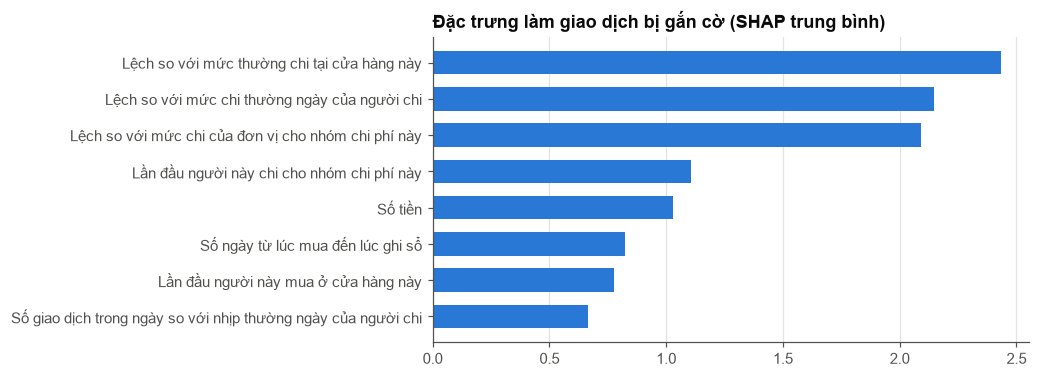

In [13]:
flagged = X_real.loc[df.index[test_mask & df.anomaly_tx_flag].intersection(X_real.index)]
t0 = time.time()
explainer = shap.TreeExplainer(model)
sv = -pd.DataFrame(explainer.shap_values(flagged[FEATURES]), index=flagged.index, columns=FEATURES)  # dương = bất thường hơn
print(f'SHAP cho {len(flagged):,} giao dịch: {time.time() - t0:.1f} giây')

imp = sv.clip(lower=0).mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([FEATURE_NAMES[f] for f in imp.index], imp.values, color=BLUE, height=0.65)
ax.set_title('Đặc trưng làm giao dịch bị gắn cờ (SHAP trung bình)'); ax.grid(axis='y', visible=False)
plt.show()

In [14]:
def reasons(idx):
    return ' | '.join(explain(X_real.loc[idx], sv.loc[idx]))

ex_ids = df.index[only_model & df.anomaly_tx_flag].intersection(sv.index)
examples = df.loc[ex_ids].sort_values('anomaly_score', ascending=False).head(8)
examples.assign(ly_do=[reasons(i) for i in examples.index])[['merchant', 'item_desc', 'amount', 'ly_do']] \
    .rename(columns={'ly_do': 'Lý do (từ SHAP)'}).style.format({'amount': '${:,.2f}'}).hide(axis='index')

merchant,item_desc,amount,Lý do (từ SHAP)
HOLIDAY INN EXPRESS OKC,ROOM CHARGES,"$4,614.99","Số tiền $4,614.99 gấp 26.8 lần mức chi thường gặp tại cửa hàng này | Số tiền $4,614.99 gấp 31.8 lần mức chi thường gặp của người chi này | Số tiền $4,614.99 gấp 26.6 lần mức chi thường gặp của đơn vị cho nhóm chi phí này"
COLLEGE TRANSCRIPT,GENERAL PURCHASE,$525.95,Số tiền $525.95 gấp 20.4 lần mức chi thường gặp tại cửa hàng này | Số tiền $525.95 gấp 58.6 lần mức chi thường gặp của người chi này | Lần đầu người này mua ở cửa hàng này
LAB AIDS INC,NONDURABLE GOODS EA,"$4,011.17","Số tiền $4,011.17 gấp 11.8 lần mức chi thường gặp của người chi này | Số tiền $4,011.17 gấp 13.9 lần mức chi thường gặp tại cửa hàng này | Số tiền $4,011.17 gấp 51.2 lần mức chi thường gặp của đơn vị cho nhóm chi phí này"
CHICKASAW RETREAT & CO,ROOM CHARGES,"$2,120.00","Ghi sổ sau 27 ngày kể từ ngày mua | Số tiền $2,120.00 gấp 12.0 lần mức chi thường gặp tại cửa hàng này | Số tiền $2,120.00 gấp 14.5 lần mức chi thường gặp của đơn vị cho nhóm chi phí này"
OVERLEAF EDITOR,Standard group with edu di item,"$4,750.00","Số tiền $4,750.00 gấp 32.5 lần mức chi thường gặp tại cửa hàng này | Số tiền $4,750.00 gấp 54.2 lần mức chi thường gặp của đơn vị cho nhóm chi phí này | Lần đầu người này chi cho nhóm chi phí này"
HOLIDAY INN EXPRESS,ROOM CHARGES,"$3,958.68","Số tiền $3,958.68 gấp 22.9 lần mức chi thường gặp tại cửa hàng này | Lần đầu người này chi cho nhóm chi phí này | Số tiền lớn: $3,958.68"
WF WAYFAIR4740638489,DILKUSH UPHOLSTERED 50 98 PC|CHAMPLAIN COFFEE TABL,"$4,950.86","Số tiền $4,950.86 gấp 67.3 lần mức chi thường gặp của người chi này | Lần đầu người này chi cho nhóm chi phí này | Số tiền $4,950.86 gấp 24.9 lần mức chi thường gặp của đơn vị cho nhóm chi phí này"
WHOLESALE ELECTRIC SUPPLY,GENERAL PURCHASE,$751.10,Số tiền $751.10 gấp 7.2 lần mức chi thường gặp tại cửa hàng này | Số tiền $751.10 gấp 7.9 lần mức chi thường gặp của người chi này | Lần đầu người này chi cho nhóm chi phí này


**Nhận xét:** các giao dịch trên **không vi phạm rule nào**, nhưng bị mô hình chỉ ra với lý do cụ thể, ví dụ số tiền gấp nhiều lần mức thường chi của chính người đó, hay lần đầu chi cho một loại chi phí. Kế toán vẫn là người quyết định có xem xét hay không; mô hình chỉ đưa giao dịch vào danh sách cần review.

## 7. Mức rủi ro cuối cùng

Mức cuối cùng là mức cao hơn giữa rule và mô hình (`src/risk.py`). Mô hình bất thường không có nhãn, nên chỉ được nâng giao dịch lên tối đa **"Cần review"**. Mức **"Cảnh báo cao"** chỉ đến từ vi phạm rule mức Cao, tức các điều kiện chắc chắn.

In [15]:
df['final_level'] = combine_risk(df['rule_level'], df['anomaly_flag'])
pd.DataFrame({'Chỉ rule': df.rule_level.value_counts(normalize=True),
              'Rule + mô hình bất thường': df.final_level.value_counts(normalize=True)}).reindex(LEVELS).style.format('{:.1%}')

,Chỉ rule,Rule + mô hình bất thường
Bình thường,92.1%,84.9%
Cần review,4.4%,11.7%
Cảnh báo cao,3.4%,3.4%


Đếm theo **giao dịch**, tỷ lệ "Cần review" tăng mạnh vì một ngày mua dồn có thể gồm hàng chục giao dịch. Nhưng trong thực tế kế toán xem **cả cụm như một hồ sơ**. Vì vậy cần đo khối lượng công việc theo **số hồ sơ cần xem**: mỗi ngày mua dồn bị gắn cờ là một hồ sơ, các giao dịch cần review còn lại mỗi giao dịch là một hồ sơ.

In [16]:
t = df[test_mask]
rule_cases = (t.rule_level != 'Bình thường').sum()
day_cases = t[t.burst_day_flag].groupby(['cardholder_id', 'tx_date']).ngroups
other_cases = ((t.final_level != 'Bình thường') & ~t.burst_day_flag).sum()
n_months = t.month.nunique()
pd.DataFrame({
    'Hồ sơ cần xem / tháng': [rule_cases / n_months, (day_cases + other_cases) / n_months],
    'Trong đó: cụm mua dồn': [0, day_cases / n_months],
}, index=['Chỉ rule', 'Rule + 2 mô hình bất thường']).round(0).astype(int)

,Hồ sơ cần xem / tháng,Trong đó: cụm mua dồn
Chỉ rule,3186,0
Rule + 2 mô hình bất thường,3186,152


**Nhận xét:** tính theo hồ sơ, khối lượng công việc **gần như không đổi**, vì mỗi hồ sơ cụm mua dồn gộp luôn các vi phạm rule rải rác trong ngày đó. Ứng dụng vì vậy sẽ hiển thị cụm mua dồn như **một mục review**, kèm danh sách giao dịch bên trong.

## 8. Lưu kết quả

In [17]:
(ROOT / 'models').mkdir(exist_ok=True)
joblib.dump({'model': model, 'features': FEATURES, 'threshold': float(threshold)}, ROOT / 'models' / 'anomaly_iforest.joblib')
joblib.dump({'model': day_model, 'features': DAY_FEATURES, 'threshold': float(day_threshold)}, ROOT / 'models' / 'anomaly_day_iforest.joblib')
out = ROOT / 'data' / 'processed'
out.mkdir(exist_ok=True)
df[['txn_id', 'anomaly_score', 'anomaly_tx_flag', 'burst_day_flag', 'anomaly_flag', 'rule_level', 'final_level']].to_csv(out / 'risk_levels.csv', index=False)
print(f'Ngưỡng điểm bất thường: {threshold:.4f}')
for f in [ROOT / 'models' / 'anomaly_iforest.joblib', ROOT / 'models' / 'anomaly_day_iforest.joblib', out / 'risk_levels.csv']:
    print(f.name, f'{f.stat().st_size / 1e6:.1f} MB')

Ngưỡng điểm bất thường: 0.5825
anomaly_iforest.joblib 17.8 MB
anomaly_day_iforest.joblib 16.8 MB
risk_levels.csv 40.3 MB


## 9. Kết luận

1. **Isolation Forest với 8 đặc trưng theo thói quen chi tiêu** tốt hơn rõ rệt so với mốc z-score, và tốt hơn cả khi dùng nhiều đặc trưng hơn. Chọn đặc trưng quan trọng hơn thêm đặc trưng.
2. **Mô hình bổ sung cho rule:** bắt được những bất thường mà rule không có điều kiện để bắt (số tiền lạ với người chi, loại chi phí chưa từng chi, ghi sổ trễ). Kết hợp cả hai cho độ phủ cao hơn hẳn.
3. **SHAP + `explain()`** chuyển kết quả mô hình thành lý do tiếng Việt có số liệu. Cùng với thông báo vi phạm rule, đây là đầu vào có cấu trúc cho LLM ở bước giải thích.
4. **Bất thường theo cụm** (mua dồn dập) không bắt được ở cấp giao dịch, nhưng bắt được gần như toàn bộ khi thêm mô hình **cấp người chi × ngày** dựa trên nhịp mua của chính người đó.
5. **Hạn chế:** đánh giá dựa trên bất thường giả lập, không phải gian lận thật; các ngưỡng (top 1%) cần được hiệu chỉnh với phản hồi thực tế của kế toán.